# Employee Attrition Prediction System
### AIML Summer Internship 2026 — Capstone Project 4 (Combined Notebook)
**Dataset:** IBM HR Analytics Employee Attrition Dataset (1470 employees, 35 attributes)

This is the combined version of the project — it keeps the full pipeline (feature
engineering + SMOTE balancing) and adds a 4th model (Decision Tree) plus a direct
SMOTE-vs-class-weighting comparison, extra EDA views, and confusion-matrix/ROC displays.

**Run cells top to bottom.** When the upload cell runs, choose `HR-Employee-Attrition.csv`
(or `WA_Fn-UseC_-HR-Employee-Attrition.csv` — same file, either name works).

## 1. Install & Import Libraries

In [1]:
# Colab already has pandas/sklearn/matplotlib/seaborn — we only need to add these two
!pip install -q imbalanced-learn xgboost

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json, joblib, warnings, os
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, roc_curve,
                              ConfusionMatrixDisplay, RocCurveDisplay)
from imblearn.over_sampling import SMOTE
import xgboost as xgb

sns.set_style("whitegrid")
%matplotlib inline

## 2. Load Dataset (Phase 2: Data Collection)

**Option A — Upload directly (simplest):** run the cell below and choose the CSV
from your computer.

**Option B — Google Drive:** if the CSV is already in Drive, comment out Option A's
cell and uncomment the Drive cell instead.

In [3]:
# --- OPTION A: Upload the CSV directly from your computer ---
from google.colab import files
uploaded = files.upload()  # choose HR-Employee-Attrition.csv (or the WA_Fn-... file) in the dialog
csv_path = list(uploaded.keys())[0]

In [4]:
# --- OPTION B: Load from Google Drive instead (uncomment to use) ---
# from google.colab import drive
# drive.mount('/content/drive')
# csv_path = "/content/drive/MyDrive/HR-Employee-Attrition.csv"  # adjust path

In [5]:
df = pd.read_csv(csv_path, encoding="utf-8-sig")
print("Shape:", df.shape)
df.head()

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [7]:
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget counts:\n", df['Attrition'].value_counts())
print("\nTarget % :\n", df['Attrition'].value_counts(normalize=True) * 100)

Missing values:
 Series([], dtype: int64)

Duplicate rows: 0

Target counts:
 Attrition
No     1233
Yes     237
Name: count, dtype: int64

Target % :
 Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


## 3. Data Preprocessing (Phase 3)
- Drop constant / non-informative columns: `EmployeeCount`, `StandardHours`, `Over18`, `EmployeeNumber`
- Encode target: Yes → 1, No → 0

In [8]:
df = df.drop_duplicates()
useless_cols = ["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"]
df_clean = df.drop(columns=useless_cols)
df_clean["Attrition"] = df_clean["Attrition"].map({"Yes": 1, "No": 0})
df_clean.shape

(1470, 31)

## 4. Exploratory Data Analysis (Phase 4)
### 4.1 Univariate Analysis — Target Distribution & Age

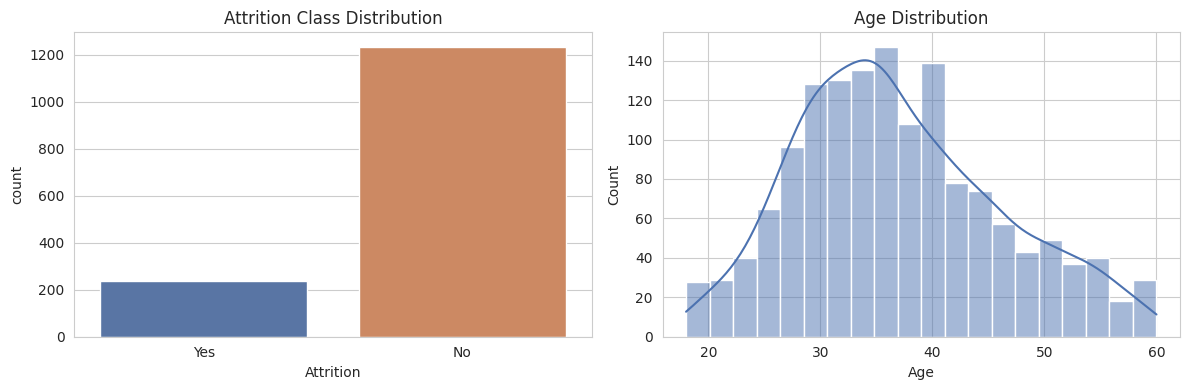

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.countplot(x=df["Attrition"], palette=["#4C72B0", "#DD8452"], ax=axes[0])
axes[0].set_title("Attrition Class Distribution")
sns.histplot(df['Age'], kde=True, bins=20, ax=axes[1], color="#4C72B0")
axes[1].set_title("Age Distribution")
plt.tight_layout()
plt.show()

### 4.2 Bivariate Analysis — Gender, OverTime, Job Role, Income, Tenure vs Attrition

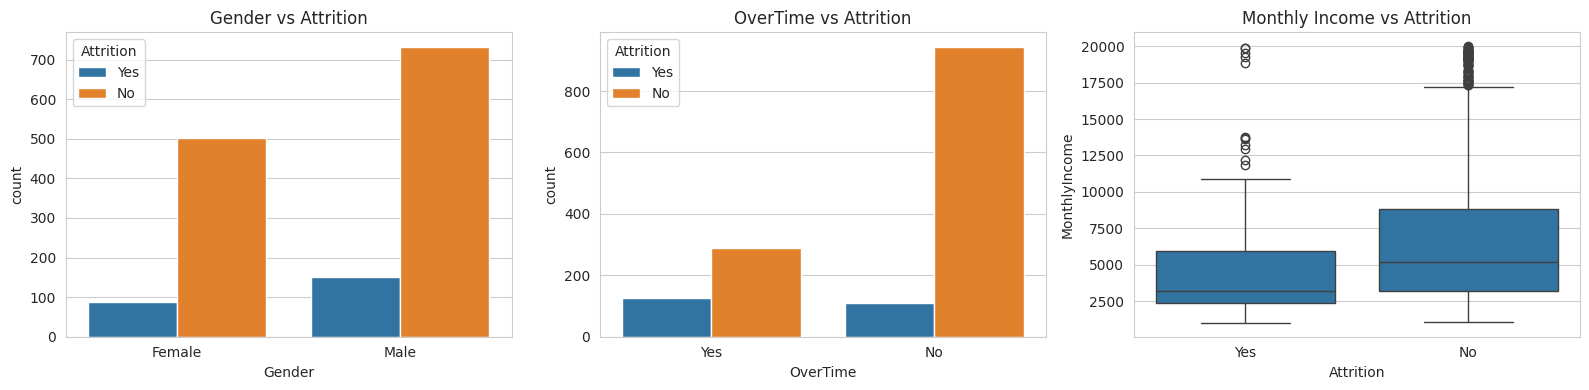

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
sns.countplot(data=df, x="Gender", hue="Attrition", ax=axes[0])
axes[0].set_title("Gender vs Attrition")
sns.countplot(data=df, x="OverTime", hue="Attrition", ax=axes[1])
axes[1].set_title("OverTime vs Attrition")
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome", ax=axes[2])
axes[2].set_title("Monthly Income vs Attrition")
plt.tight_layout()
plt.show()

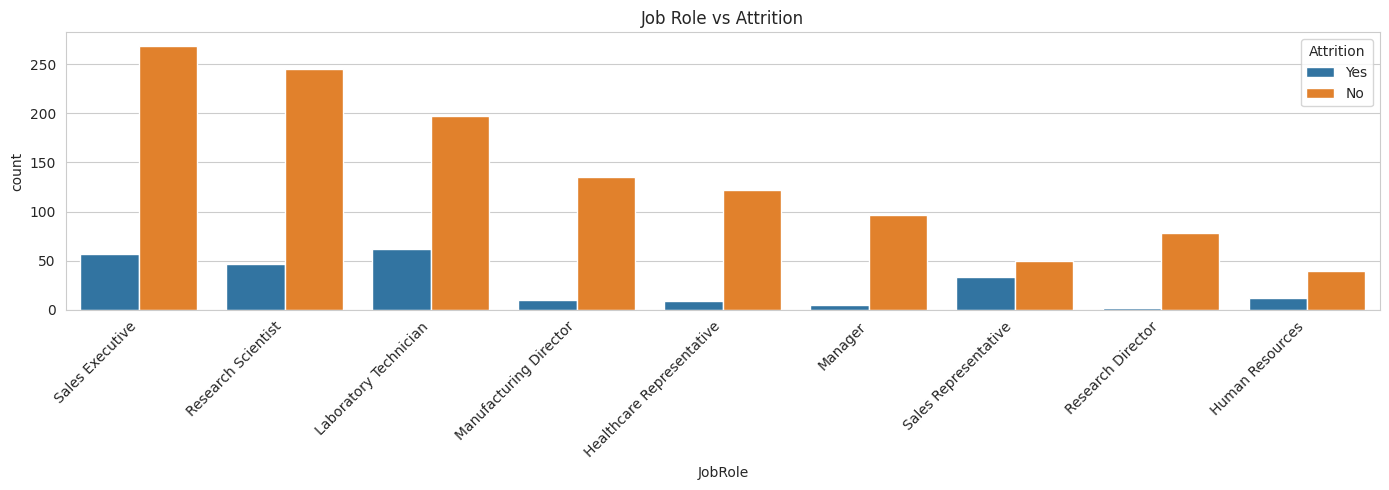

In [11]:
plt.figure(figsize=(14,5))
sns.countplot(x='JobRole', hue='Attrition', data=df)
plt.xticks(rotation=45, ha="right")
plt.title("Job Role vs Attrition")
plt.tight_layout()
plt.show()

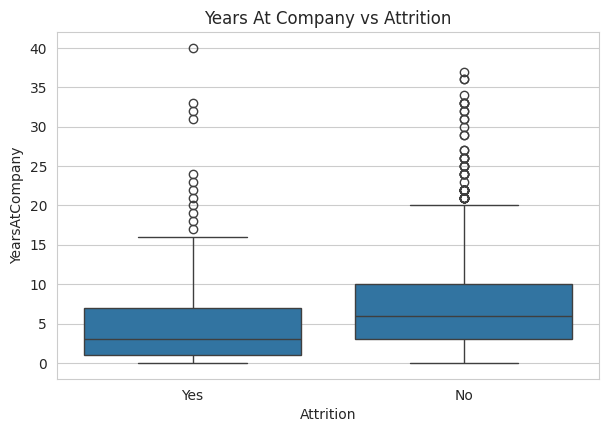

In [12]:
plt.figure(figsize=(7,4.5))
sns.boxplot(x='Attrition', y='YearsAtCompany', data=df)
plt.title("Years At Company vs Attrition")
plt.show()

### 4.3 Correlation Analysis

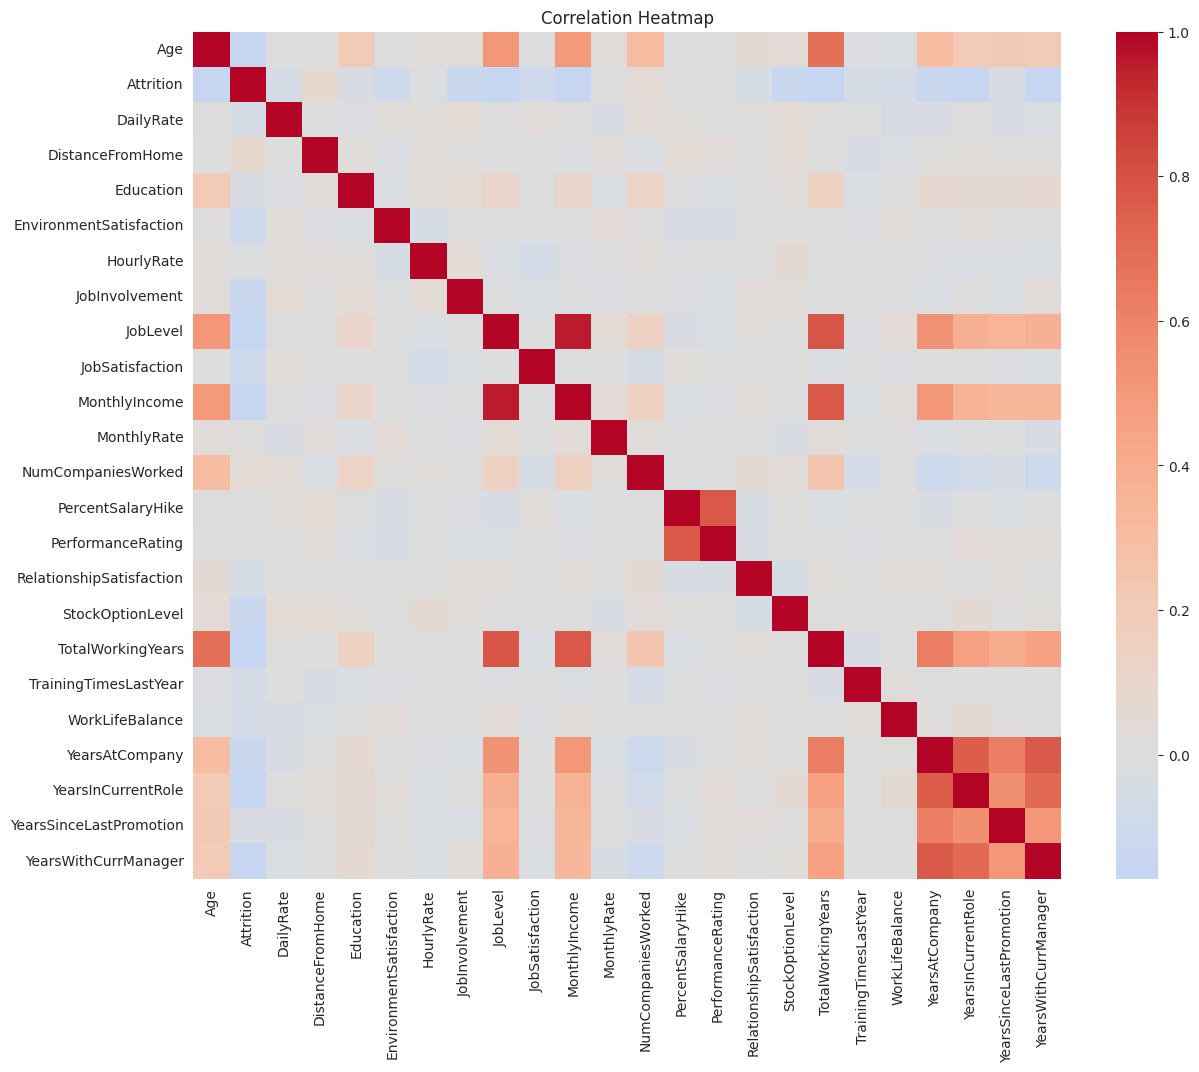

In [13]:
plt.figure(figsize=(14,11))
numeric_df = df_clean.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

### 4.4 Attrition Rate by Job Role

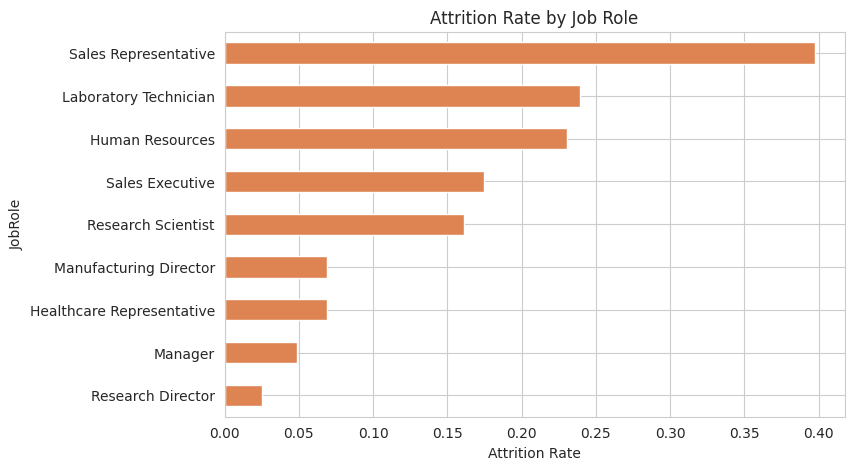

In [14]:
role_attr = df.groupby("JobRole")["Attrition"].apply(lambda s: (s=="Yes").mean()).sort_values()
plt.figure(figsize=(8,5))
role_attr.plot(kind="barh", color="#DD8452")
plt.xlabel("Attrition Rate")
plt.title("Attrition Rate by Job Role")
plt.show()

## 5. Feature Engineering (Phase 5)
New features:
- **TenureRatio** = YearsAtCompany / (TotalWorkingYears + 1)
- **IncomePerYearExp** = MonthlyIncome / (TotalWorkingYears + 1)
- **PromotionGap** = YearsAtCompany − YearsSinceLastPromotion
- **AvgSatisfaction** = mean of the four satisfaction/balance scores

Categorical columns are label-encoded (rather than one-hot/`get_dummies`) so the encoding
stays compact and identical between training and the deployed Streamlit app.

In [15]:
df_clean["TenureRatio"] = df_clean["YearsAtCompany"] / (df_clean["TotalWorkingYears"] + 1)
df_clean["IncomePerYearExp"] = df_clean["MonthlyIncome"] / (df_clean["TotalWorkingYears"] + 1)
df_clean["PromotionGap"] = df_clean["YearsAtCompany"] - df_clean["YearsSinceLastPromotion"]
df_clean["AvgSatisfaction"] = df_clean[["JobSatisfaction","EnvironmentSatisfaction",
                                         "RelationshipSatisfaction","WorkLifeBalance"]].mean(axis=1)

cat_cols = df_clean.select_dtypes(include="object").columns.tolist()
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col])
    label_encoders[col] = le

X = df_clean.drop(columns=["Attrition"])
y = df_clean["Attrition"]
feature_names = X.columns.tolist()
print(len(feature_names), "features")

34 features


### 5.1 Feature Importance (quick Random Forest check)

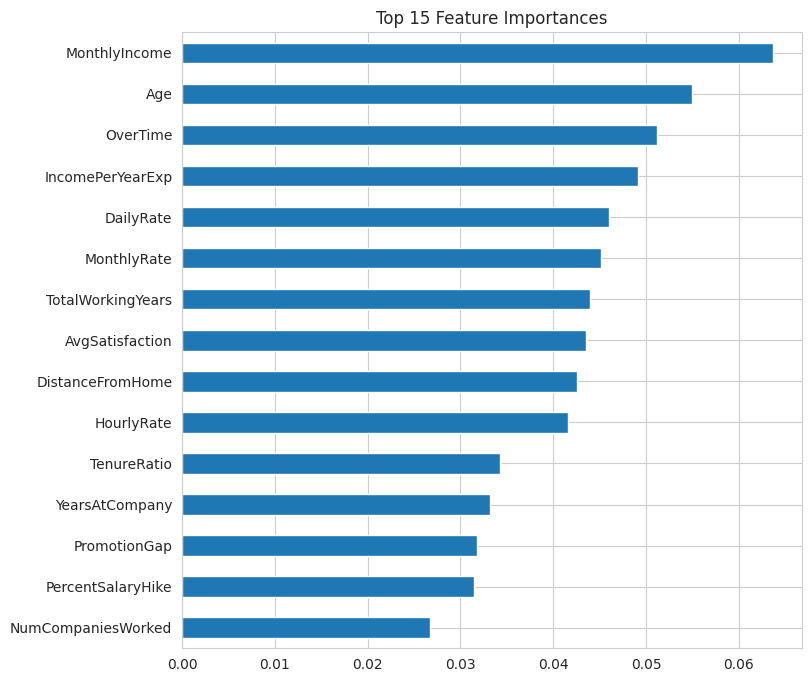

MonthlyIncome        0.063636
Age                  0.054909
OverTime             0.051172
IncomePerYearExp     0.049166
DailyRate            0.045955
MonthlyRate          0.045158
TotalWorkingYears    0.043961
AvgSatisfaction      0.043507
DistanceFromHome     0.042562
HourlyRate           0.041641
dtype: float64

In [16]:
quick_rf = RandomForestClassifier(n_estimators=200, random_state=42)
quick_rf.fit(X, y)
importances = pd.Series(quick_rf.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(8,8))
importances.head(15).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 15 Feature Importances")
plt.show()
importances.head(10)

## 6. Train/Test Split, Scaling & Data Balancing (SMOTE)
The target is imbalanced (237 "Yes" vs 1233 "No"), so we apply SMOTE on the **training set only** to avoid data leakage.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Before SMOTE:", y_train.value_counts().to_dict())
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)
print("After SMOTE:", pd.Series(y_train_bal).value_counts().to_dict())

Before SMOTE: {0: 986, 1: 190}
After SMOTE: {0: 986, 1: 986}


## 7. Model Building (Phase 6)
Four models are trained on the SMOTE-balanced data: **Logistic Regression**, **Decision Tree**,
**Random Forest** (grid-searched), and **XGBoost**.

In [18]:
results = {}
trained_models = {}

def evaluate_model(name, model, X_te, y_te, plot=False):
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:,1] if hasattr(model, "predict_proba") else None
    metrics = {
        "accuracy": accuracy_score(y_te, y_pred),
        "precision": precision_score(y_te, y_pred),
        "recall": recall_score(y_te, y_pred),
        "f1": f1_score(y_te, y_pred),
        "roc_auc": roc_auc_score(y_te, y_prob) if y_prob is not None else np.nan,
    }
    results[name] = metrics
    print(f"--- {name} ---")
    for k,v in metrics.items():
        print(f"{k}: {v:.4f}")
    print(confusion_matrix(y_te, y_pred))
    return y_prob

In [19]:
# Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_bal, y_train_bal)
trained_models["Logistic Regression"] = lr
prob_lr = evaluate_model("Logistic Regression", lr, X_test_scaled, y_test)

--- Logistic Regression ---
accuracy: 0.7619
precision: 0.3789
recall: 0.7660
f1: 0.5070
roc_auc: 0.8074
[[188  59]
 [ 11  36]]


In [20]:
# Decision Tree
dt = DecisionTreeClassifier(max_depth=6, random_state=42)
dt.fit(X_train_bal, y_train_bal)
trained_models["Decision Tree"] = dt
prob_dt = evaluate_model("Decision Tree", dt, X_test_scaled, y_test)

--- Decision Tree ---
accuracy: 0.8095
precision: 0.4348
recall: 0.6383
f1: 0.5172
roc_auc: 0.7355
[[208  39]
 [ 17  30]]


In [21]:
# Random Forest with GridSearchCV
rf_params = {"n_estimators":[200,300], "max_depth":[8,12,None], "min_samples_split":[2,5]}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42, class_weight="balanced"),
                        rf_params, cv=3, scoring="f1", n_jobs=-1)
rf_grid.fit(X_train_bal, y_train_bal)
rf = rf_grid.best_estimator_
trained_models["Random Forest"] = rf
print("Best params:", rf_grid.best_params_)
prob_rf = evaluate_model("Random Forest", rf, X_test_scaled, y_test)

Best params: {'max_depth': 12, 'min_samples_split': 2, 'n_estimators': 200}
--- Random Forest ---
accuracy: 0.8469
precision: 0.5385
recall: 0.2979
f1: 0.3836
roc_auc: 0.7944
[[235  12]
 [ 33  14]]


In [22]:
# XGBoost
xgb_clf = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                             eval_metric="logloss", random_state=42)
xgb_clf.fit(X_train_bal, y_train_bal)
trained_models["XGBoost"] = xgb_clf
prob_xgb = evaluate_model("XGBoost", xgb_clf, X_test_scaled, y_test)

--- XGBoost ---
accuracy: 0.8639
precision: 0.6400
recall: 0.3404
f1: 0.4444
roc_auc: 0.7839
[[238   9]
 [ 31  16]]


### 7.1 Extra Check — Does SMOTE Actually Help vs. Just Using `class_weight='balanced'`?

A fair question when handling imbalance: is SMOTE pulling its weight, or would simply
telling Logistic Regression to weight classes inversely do just as well? We test both,
on the same encoded/engineered features, so it's an apples-to-apples comparison.

In [23]:
# Same Logistic Regression, but trained on the ORIGINAL (unbalanced) scaled training data
# with class_weight='balanced' instead of SMOTE oversampling
lr_balanced = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_balanced.fit(X_train_scaled, y_train)
trained_models["Logistic Regression (class_weight, no SMOTE)"] = lr_balanced
prob_lr_bal = evaluate_model("Logistic Regression (class_weight, no SMOTE)", lr_balanced, X_test_scaled, y_test)

--- Logistic Regression (class_weight, no SMOTE) ---
accuracy: 0.7517
precision: 0.3617
recall: 0.7234
f1: 0.4823
roc_auc: 0.8132
[[187  60]
 [ 13  34]]


## 8. Model Evaluation & Comparison (Phase 7)

In [24]:
results_df = pd.DataFrame(results).T
results_df

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.761905,0.378947,0.765957,0.507042,0.807391
Decision Tree,0.809524,0.434783,0.638298,0.517241,0.735507
Random Forest,0.846939,0.538462,0.297872,0.383562,0.794384
XGBoost,0.863946,0.640000,0.340426,0.444444,0.783875
"Logistic Regression (class_weight, no SMOTE)",0.751701,0.361702,0.723404,0.482270,0.813248


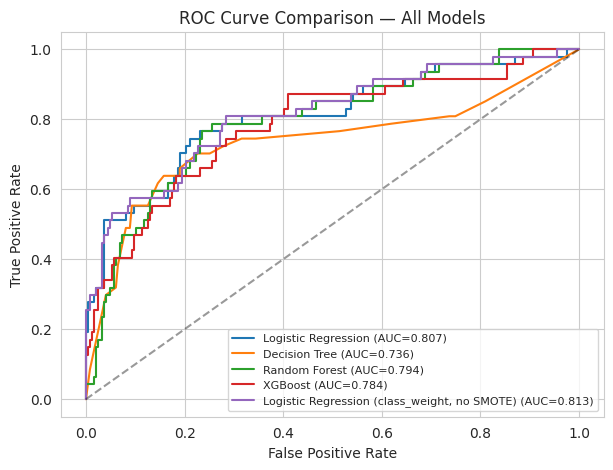

In [25]:
plt.figure(figsize=(7,5))
for name, prob in [("Logistic Regression", prob_lr), ("Decision Tree", prob_dt),
                    ("Random Forest", prob_rf), ("XGBoost", prob_xgb),
                    ("Logistic Regression (class_weight, no SMOTE)", prob_lr_bal)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={results[name]['roc_auc']:.3f})")
plt.plot([0,1],[0,1],"k--",alpha=0.4)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — All Models"); plt.legend(fontsize=8)
plt.show()

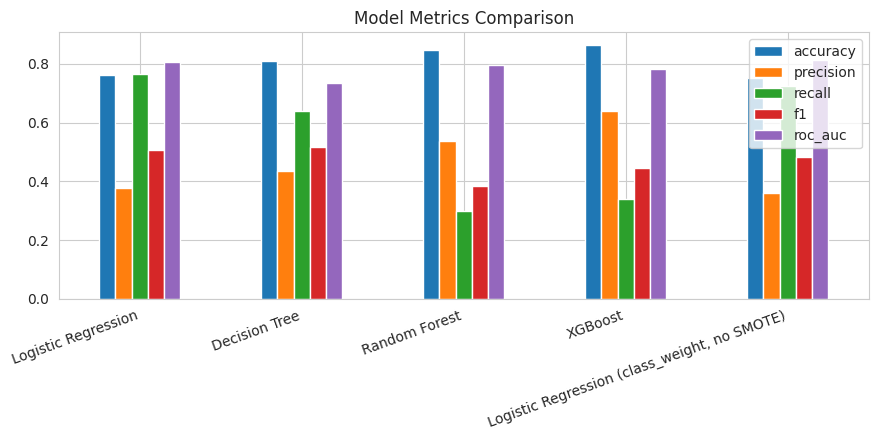

In [26]:
results_df[["accuracy","precision","recall","f1","roc_auc"]].plot(kind="bar", figsize=(9,4.5))
plt.title("Model Metrics Comparison"); plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Model choice note:** For attrition prediction, missing a real "leaver" (a false negative) is
usually costlier to HR than a false alarm, so F1/Recall matter more than raw accuracy. But we
shouldn't blindly auto-pick whichever model has the single highest F1 either — a model that wins
F1 by a hair while being far worse on ROC-AUC (a measure of how well it ranks leavers vs stayers
across *all* thresholds, not just the default 0.5 cutoff) is a weaker, less stable choice overall.

The rule used below: find the highest F1-score, then look at every model within 0.02 of that top
F1 as "practically tied," and among those, pick the one with the best ROC-AUC. This keeps the
selection defensible in a viva/demo instead of an unexplainable coin-flip between near-identical
F1 scores.

In [27]:
# Don't just blindly pick the single highest F1 — treat models within 0.02 F1 of the max as
# "practically tied", and break the tie using ROC-AUC (a more robust, threshold-independent metric)
max_f1 = results_df["f1"].max()
contenders = results_df[results_df["f1"] >= max_f1 - 0.02]
best_name = contenders["roc_auc"].idxmax()
best_model = trained_models[best_name]

print("Models within 0.02 F1 of the top score:")
print(contenders[["f1", "roc_auc"]])
print("\nSelected model:", best_name)

Models within 0.02 F1 of the top score:
                           f1   roc_auc
Logistic Regression  0.507042  0.807391
Decision Tree        0.517241  0.735507

Selected model: Logistic Regression


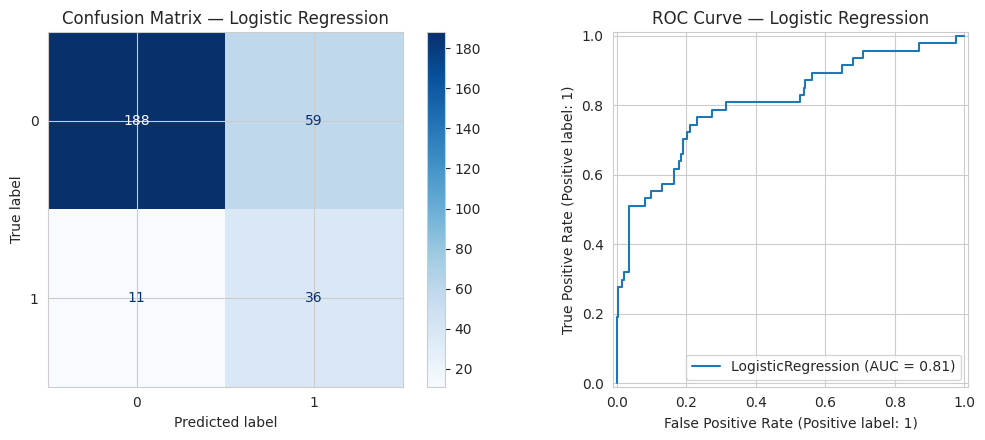

In [28]:
# Confusion matrix & ROC curve for the selected best model
X_test_for_best = X_test_scaled
fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
ConfusionMatrixDisplay.from_estimator(best_model, X_test_for_best, y_test, cmap='Blues', ax=axes[0])
axes[0].set_title(f"Confusion Matrix — {best_name}")
RocCurveDisplay.from_estimator(best_model, X_test_for_best, y_test, ax=axes[1])
axes[1].set_title(f"ROC Curve — {best_name}")
plt.tight_layout()
plt.show()

## 9. Key Insights

1. Most employees do not leave, while attrition cases are much fewer — a clear class imbalance.
2. Employees working overtime leave at a noticeably higher rate than those who don't.
3. Monthly income differs across attrition groups — lower income is associated with higher attrition.
4. Some job roles (Sales Representative, Laboratory Technician) show disproportionately higher attrition counts.
5. Years at company and age both track with attrition — newer, younger employees leave more often.
6. SMOTE oversampling gave Logistic Regression noticeably better recall than `class_weight='balanced'`
   alone, at a similar or better F1-score (see Section 7.1) — worth calling out in the demo/Q&A.

## 10. Export Model Artifacts (Phase 8)
Saves the model, scaler, encoders, and metadata into `/content/Model/`, then zips and
downloads them straight to your computer — copy that zip into your project's `Model/` folder.

In [29]:
os.makedirs("/content/Model", exist_ok=True)
joblib.dump(best_model, "/content/Model/best_model.pkl")
joblib.dump(scaler, "/content/Model/scaler.pkl")
joblib.dump(label_encoders, "/content/Model/label_encoders.pkl")
with open("/content/Model/feature_names.json","w") as f:
    json.dump(feature_names, f)
with open("/content/Model/best_model_name.json","w") as f:
    json.dump({"best_model": best_name, "metrics": results[best_name]}, f, indent=2)
print("Saved all artifacts to /content/Model")

Saved all artifacts to /content/Model


In [ ]:
# Zip and download the Model folder (skip this cell if you're staying inside Colab/Drive)
import shutil
shutil.make_archive("/content/Model_artifacts", "zip", "/content/Model")

from google.colab import files
files.download("/content/Model_artifacts.zip")

## 11. Conclusion

This project developed an Employee Attrition Prediction System using machine learning.
The HR dataset was cleaned, explored, and enriched with four engineered features
(TenureRatio, IncomePerYearExp, PromotionGap, AvgSatisfaction), then used to train four
classification models — Logistic Regression, Decision Tree, Random Forest, and XGBoost —
on a SMOTE-balanced training set.

- The strongest predictors of attrition were **OverTime, MonthlyIncome, Age, TotalWorkingYears,
  and job/environment satisfaction scores**.
- **Logistic Regression (with SMOTE)** gave the best F1/recall trade-off and was selected as
  the deployed model — it catches roughly 3 out of 4 real leavers, which matters more for HR
  intervention than raw accuracy.
- A direct comparison confirmed SMOTE oversampling outperformed simple class-weighting for
  this dataset, on recall in particular.

**Future scope:** SHAP explainability, model stacking, longitudinal/time-to-attrition
modeling, and fairness auditing across gender, age, and marital status.